In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Customers.csv to Customers.csv


In [ ]:
import pandas as pd
df = pd.read_csv('/content/Customers.csv')

In [ ]:
df.head()

,Customer_ID,Customer_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUS00001,Vivek Kumar,Male,26,vivek.kumar.00001@example.com,1,Chennai,Tamil Nadu,2023-08-04,Regular
1,CUS00002,Anjali Trivedi,Female,40,anjali.trivedi.00002@example.com,2,Ahmedabad,Gujarat,2021-06-14,Premium
2,CUS00003,Saba Mishra,Female,60,saba.mishra.00003@example.com,3,Indore,Madhya Pradesh,2022-07-31,Regular
3,CUS00004,Aarav More,Male,40,aarav.more.00004@example.com,4,Mumbai,Maharashtra,2021-12-16,Regular
4,CUS00005,Aarav Singh,Male,23,aarav.singh.00005@example.com,5,Jaipur,Rajasthan,2021-01-28,Regular


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8016 entries, 0 to 8015
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Customer_ID        8016 non-null   object
 1   Customer_Name      7936 non-null   object
 2   Gender             8016 non-null   object
 3   Age                7933 non-null   object
 4   Email              7936 non-null   object
 5   Phone              8016 non-null   int64 
 6   City               8016 non-null   object
 7   State              8016 non-null   object
 8   Registration_Date  8016 non-null   object
 9   Customer_Segment   8016 non-null   object
dtypes: int64(1), object(9)
memory usage: 626.4+ KB


In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Customer_Name,80
Gender,0
Age,83
Email,80
Phone,0
City,0
State,0
Registration_Date,0
Customer_Segment,0


In [ ]:
df = df.drop('Customer_Name',axis = 1)

In [ ]:
df['Age'].unique()

array(['26', '40', '60', '23', '62', '46', '38', '30', '43', '27', '59',
       '42', '51', '61', '33', '28', '41', '32', '34', '29', '50', '70',
       '25', '63', '35', '56', '36', '52', '31', '47', '39', '48', '22',
       '53', '54', '65', '37', '76', '49', '44', '45', '55', '58', nan,
       '73', '57', '20', '78', '24', '81', '67', '75', '72', '64', '21',
       '85', '71', '68', '-3', '83', '74', '80', '77', '69', '86', '19',
       '-21', '66', '-14', '84', '126', '-5', '79', '18', '-2', '158',
       '-15', '-10', '82', '44 pcs', '-8', 'unknown', '135', '28 pcs',
       '174', '24 pcs', 'three', '173', '67 pcs', '147', '164', '-20',
       '-4', '49 units'], dtype=object)

In [ ]:
import numpy as np
df['Age']= df['Age'].replace('unknown',np.nan)

In [ ]:
df['Age']= df['Age'].replace('three',np.nan)

In [ ]:
df['Age'] = df['Age'].astype(str).str.replace(r'\s*(pcs|units)', '', regex=True)

In [ ]:
df['Age'].unique()

array(['26', '40', '60', '23', '62', '46', '38', '30', '43', '27', '59',
       '42', '51', '61', '33', '28', '41', '32', '34', '29', '50', '70',
       '25', '63', '35', '56', '36', '52', '31', '47', '39', '48', '22',
       '53', '54', '65', '37', '76', '49', '44', '45', '55', '58', 'nan',
       '73', '57', '20', '78', '24', '81', '67', '75', '72', '64', '21',
       '85', '71', '68', '-3', '83', '74', '80', '77', '69', '86', '19',
       '-21', '66', '-14', '84', '126', '-5', '79', '18', '-2', '158',
       '-15', '-10', '82', '-8', '135', '174', '173', '147', '164', '-20',
       '-4'], dtype=object)

In [ ]:
from sklearn.impute import SimpleImputer

si = SimpleImputer(strategy= 'median')

df['Age'] = si.fit_transform(df[['Age']])

In [ ]:
df['Age'] = df['Age'].abs()

In [ ]:
df = df[df['Age'].between(10, 90)]

In [ ]:
df['Age'].unique()

array([26., 40., 60., 23., 62., 46., 38., 30., 43., 27., 59., 42., 51.,
       61., 33., 28., 41., 32., 34., 29., 50., 70., 25., 63., 35., 56.,
       36., 52., 31., 47., 39., 48., 22., 53., 54., 65., 37., 76., 49.,
       44., 45., 55., 58., 73., 57., 20., 78., 24., 81., 67., 75., 72.,
       64., 21., 85., 71., 68., 83., 74., 80., 77., 69., 86., 19., 66.,
       14., 84., 79., 18., 15., 10., 82.])

In [ ]:
df['Age'] = df['Age'].astype(int)

In [ ]:
df['Gender'].unique()

array(['Male', 'Female', 'Other', 'male', 'F', ' Male  ', 'female',
       'FEMALE', '  Female', ' Female  ', 'MALE', 'Female ', 'Male ',
       '  Male', ' Other  '], dtype=object)

In [ ]:
df['Gender'] = df['Gender'].str.strip()
df['Gender'] = df['Gender'].str.capitalize()

In [ ]:
df['Gender'].unique()

array(['Male', 'Female', 'Other', 'F'], dtype=object)

In [ ]:
df['Age']= df['Age'].replace('F','Female')

In [ ]:
df['Age'].unique()

array([26, 40, 60, 23, 62, 46, 38, 30, 43, 27, 59, 42, 51, 61, 33, 28, 41,
       32, 34, 29, 50, 70, 25, 63, 35, 56, 36, 52, 31, 47, 39, 48, 22, 53,
       54, 65, 37, 76, 49, 44, 45, 55, 58, 73, 57, 20, 78, 24, 81, 67, 75,
       72, 64, 21, 85, 71, 68, 83, 74, 80, 77, 69, 86, 19, 66, 14, 84, 79,
       18, 15, 10, 82])

In [ ]:
df['Email'].unique()

array(['vivek.kumar.00001@example.com',
       'anjali.trivedi.00002@example.com',
       'saba.mishra.00003@example.com', ...,
       'aparna.thomas.07998@example.com', 'shruti.naik.07999@example.com',
       'arindam.saha.08000@example.com'], shape=(7906,), dtype=object)

In [ ]:
df = df.drop('Email',axis =1)

In [ ]:
df['Phone'].unique()

array([   1,    2,    3, ..., 7998, 7999, 8000], shape=(7985,))

In [ ]:
df['City'].unique()

array(['Chennai', 'Ahmedabad', 'Indore', 'Mumbai', 'Jaipur', 'Pune',
       'Hyderabad', 'Bengaluru', 'Kolkata ', 'Kozhikode', 'Delhi',
       'Chandigarh', 'Kochi', 'Kolkata', 'Lucknow', 'Coimbatore',
       ' Ahmedabad  ', 'KOLKATA', 'delhi', 'pune', 'BENGALURU',
       'KOZHIKODE', 'chennai', '  Chennai', '  Hyderabad', ' Pune  ',
       'AHMEDABAD', 'MUMBAI', 'jaipur', 'Pune ', ' Chennai  ',
       'hyderabad', 'bengaluru', 'CHENNAI', '  Pune', 'lucknow',
       '  Delhi', 'kolkata', 'indore', 'Jaipur ', 'chandigarh',
       '  Ahmedabad', ' Kolkata  ', '  Bengaluru', 'HYDERABAD',
       '  Coimbatore', 'Mumbai ', 'coimbatore', ' Delhi  ', '  Mumbai',
       'JAIPUR', '  Kozhikode', 'kochi', 'mumbai', 'ahmedabad', 'DELHI'],
      dtype=object)

In [ ]:
df['City'] = df['City'].str.strip()
df['City'] = df['City'].str.capitalize()

In [ ]:
df['State'].unique()

array(['Tamil Nadu', 'Gujarat', 'Madhya Pradesh', 'Maharashtra',
       'Rajasthan', 'Telangana', 'Karnataka', 'West Bengal', 'Kerala',
       'Delhi', 'chandigarh', 'Uttar Pradesh', 'tamil nadu', 'Chandigarh',
       'maharashtra', ' Maharashtra  ', '  Madhya Pradesh', ' Gujarat  ',
       'TELANGANA', 'Maharashtra ', 'KARNATAKA', 'delhi', 'MAHARASHTRA',
       'telangana', 'Delhi ', ' Delhi  ', '  Maharashtra', 'WEST BENGAL',
       'West Bengal ', '  Telangana', 'karnataka', 'rajasthan', '  Delhi',
       'RAJASTHAN', '  Tamil Nadu', 'Kerala ', 'KERALA', ' Tamil Nadu  ',
       'Karnataka ', 'TAMIL NADU', 'Uttar Pradesh ', 'DELHI', 'gujarat'],
      dtype=object)

In [ ]:
df['State'] = df['State'].str.strip()
df['State'] = df['State'].str.capitalize()

In [ ]:
df['Registration_Date'].unique()

array(['2023-08-04', '2021-06-14', '2022-07-31', ..., '2023-03-23',
       '2023-08-16', '22/08/2020'], shape=(2922,), dtype=object)

In [ ]:
df['Registration_Date'] = pd.to_datetime(df['Registration_Date'], format='mixed', dayfirst=True, errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8001 entries, 0 to 8015
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Customer_ID        8001 non-null   object        
 1   Gender             8001 non-null   object        
 2   Age                8001 non-null   int64         
 3   Phone              8001 non-null   int64         
 4   City               8001 non-null   object        
 5   State              8001 non-null   object        
 6   Registration_Date  7987 non-null   datetime64[ns]
 7   Customer_Segment   8001 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 562.6+ KB


In [ ]:
df.head()

,Customer_ID,Gender,Age,Phone,City,State,Registration_Date,Customer_Segment
0,CUS00001,Male,26,1,Chennai,Tamil nadu,2023-08-04,Regular
1,CUS00002,Female,40,2,Ahmedabad,Gujarat,2021-06-14,Premium
2,CUS00003,Female,60,3,Indore,Madhya pradesh,2022-07-31,Regular
3,CUS00004,Male,40,4,Mumbai,Maharashtra,2021-12-16,Regular
4,CUS00005,Male,23,5,Jaipur,Rajasthan,2021-01-28,Regular


In [ ]:
df['Registration_Date'] = df['Registration_Date'].dt.strftime('%d-%m-%Y')

In [ ]:
df['Customer_Segment'].unique()

array(['Regular', 'Premium', 'New', 'VIP', ' Regular  ', ' New  ',
       'regular', '  Regular', 'PREMIUM', 'Regular ', 'REGULAR', 'new',
       'NEW', 'Premium ', 'vip', ' Premium  ', 'premium', '  Premium'],
      dtype=object)

In [ ]:
df['Customer_Segment'] = df['Customer_Segment'].str.strip()
df['Customer_Segment'] = df['Customer_Segment'].str.capitalize()

In [ ]:
df = df.dropna()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7987 entries, 0 to 8015
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Customer_ID        7987 non-null   object
 1   Gender             7987 non-null   object
 2   Age                7987 non-null   int64 
 3   Phone              7987 non-null   int64 
 4   City               7987 non-null   object
 5   State              7987 non-null   object
 6   Registration_Date  7987 non-null   object
 7   Customer_Segment   7987 non-null   object
dtypes: int64(2), object(6)
memory usage: 561.6+ KB


In [ ]:
df.duplicated().sum()

np.int64(16)

In [ ]:
df = df.drop_duplicates()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

col = np.array(['Age','Phone']).reshape(2,1)

def check_outliers(df,col_names):
  for c in col:
    df[c].boxplot()
    plt.show()

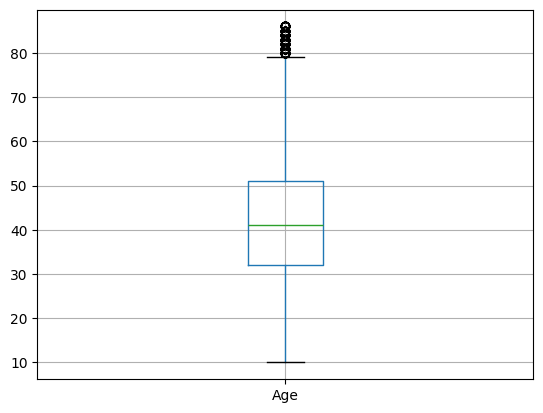

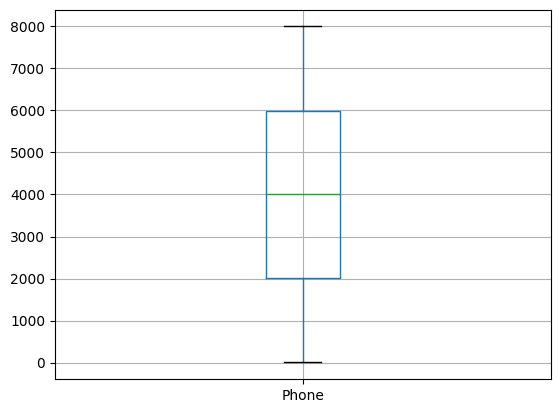

In [ ]:
check_outliers(df,col)

In [ ]:
df.to_csv('CUSTOMERS.csv', index=False)

In [ ]:
from google.colab import files
files.download('CUSTOMERS.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>